In [49]:
import argparse
import random
import sys
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [50]:
def generar_grafo_aleatorio(n, p, seed=None):
    """Genera una matriz NxN simetrica aleatoria"""
    if seed is not None:
        random.seed(seed)
    matriz = [[0] * n for _ in range(n)]
    for i in range(n):
        for j in range(i + 1, n):
            if random.random() < p:
                matriz[i][j] = 1
                matriz[j][i] = 1
    return matriz
 
 
def leer_grafo_archivo(ruta):
    with open(ruta, "r") as f:
        lineas = [l.strip() for l in f if l.strip()]
    matriz = [[int(x) for x in l.split()] for l in lineas]
 
    n = len(matriz)
    for fila in matriz:
        if len(fila) != n:
            raise ValueError("La matriz debe ser cuadrada (NxN)")
    for i in range(n):
        for j in range(n):
            if matriz[i][j] != matriz[j][i]:
                raise ValueError("La matriz debe ser simetrica")
        if matriz[i][i] != 0:
            raise ValueError("La diagonal debe ser 0")
    return matriz

In [51]:
class GraphColoringCSP:
    """
    Restricciones: nodos adyacentes no pueden compartir color
    """
 
    def __init__(self, matriz_adyacencia, num_colores):
        self.n = len(matriz_adyacencia)
        self.adj = matriz_adyacencia
        self.k = num_colores
 
        self.vecinos = {
            v: [u for u in range(self.n) if matriz_adyacencia[v][u] == 1]
            for v in range(self.n)
        }
 
        self.dominios = {v: set(range(self.k)) for v in range(self.n)}
 
        self.asignacion = {}
        self.nodos_visitados = 0   #numero de asignaciones intentadas
        self.backtracks = 0   #numero de retrocesos
 
    #heuristica
    def seleccionar_variable(self, dominios):
        no_asignadas = [v for v in range(self.n) if v not in self.asignacion]
 
        def clave(v):
            mrv = len(dominios[v])    
            grado = -len(self.vecinos[v])                 
            return (mrv, grado)
 
        return min(no_asignadas, key=clave)
 
    def ordenar_valores(self, var, dominios):
        def impacto(color):
            # cuenta cuantos vecinos no asignados perderian color
            return sum(
                1 for u in self.vecinos[var]
                if u not in self.asignacion and color in dominios[u]
            )
        return sorted(dominios[var], key=impacto)
 
    def forward_checking(self, var, color, dominios):
        """registra que se quito de donde, para poder deshacerlo"""
        cambios = []
        for u in self.vecinos[var]:
            if u not in self.asignacion and color in dominios[u]:
                dominios[u].remove(color)
                cambios.append((u, color))
                if len(dominios[u]) == 0:
                    return False, cambios
        return True, cambios
 
    def deshacer_forward_checking(self, cambios, dominios):
        for (u, color) in cambios:
            dominios[u].add(color)
 
    def es_consistente(self, var, color):
        for u in self.vecinos[var]:
            if u in self.asignacion and self.asignacion[u] == color:
                return False
        return True
 
    def resolver(self):
        dominios = {v: set(self.dominios[v]) for v in range(self.n)}
        exito = self._backtrack(dominios)
        return self.asignacion if exito else None
 
    def _backtrack(self, dominios):
        if len(self.asignacion) == self.n:
            return True
 
        var = self.seleccionar_variable(dominios)
 
        for color in self.ordenar_valores(var, dominios):
            self.nodos_visitados += 1
            if self.es_consistente(var, color):
                self.asignacion[var] = color
 
                ok, cambios = self.forward_checking(var, color, dominios)
                if ok:
                    if self._backtrack(dominios):
                        return True
 
                self.deshacer_forward_checking(cambios, dominios)
                del self.asignacion[var]
                self.backtracks += 1
 
        return False

In [52]:
def dibujar_grafo(matriz_adyacencia, asignacion, num_colores, titulo="Grafo coloreado"):
    n = len(matriz_adyacencia)
    G = nx.Graph()
    G.add_nodes_from(range(n))
    for i in range(n):
        for j in range(i + 1, n):
            if matriz_adyacencia[i][j] == 1:
                G.add_edge(i, j)
 
    paleta = plt.colormaps.get_cmap("tab20").resampled(max(num_colores, 1))
    colores_nodos = [paleta(asignacion[v]) for v in range(n)] if asignacion else "lightgray"
 
    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(7, 7))
    nx.draw(
        G, pos,
        with_labels=True,
        node_color=colores_nodos,
        node_size=700,
        font_weight="bold",
        edge_color="gray",
    )
    plt.title(titulo)
    plt.axis("off")
    plt.savefig("grafo_coloreado.png", dpi=150)
    plt.show()

In [53]:
def main():
    parser = argparse.ArgumentParser(description="coloreado de grafos")
    modo = parser.add_mutually_exclusive_group(required=True)
    modo.add_argument("--file", type=str, help="Ruta al archivo .txt con la matriz de adyacencia")
    modo.add_argument("--random", nargs=2, metavar=("N", "P"),
                       help="Generar grafo aleatorio: N nodos, P probabilidad de arista")
    parser.add_argument("--colors", type=int, required=True, help="Numero de colores disponibles (k)")
    parser.add_argument("--seed", type=int, default=None, help="Semilla aleatoria (opcional)")
    args = parser.parse_args()
 
    if args.file:
        matriz = leer_grafo_archivo(args.file)
    else:
        n = int(args.random[0])
        p = float(args.random[1])
        assert n < 21, "N debe ser menor que 21"
        matriz = generar_grafo_aleatorio(n, p, seed=args.seed)
 
    csp = GraphColoringCSP(matriz, args.colors)
    solucion = csp.resolver()
 
    if solucion is None:
        print(f"No existe solucion con {args.colors} colores para este grafo.")
    else:
        print("Solucion encontrada:")
        for v in sorted(solucion):
            print(f"  Nodo {v} -> color {solucion[v]}")
        print(f"\nNodos visitados (intentos de asignacion): {csp.nodos_visitados}")
        print(f"Backtracks: {csp.backtracks}")
        dibujar_grafo(matriz, solucion, args.colors)
 
 
if __name__ == "__main__" and not any("ipykernel" in arg for arg in sys.argv):
    main()
 

Solución encontrada:
  Nodo 0 -> color 2
  Nodo 1 -> color 0
  Nodo 2 -> color 1
  Nodo 3 -> color 0
  Nodo 4 -> color 1
  Nodo 5 -> color 2
  Nodo 6 -> color 0
  Nodo 7 -> color 1

Nodos visitados: 8
Backtracks: 0


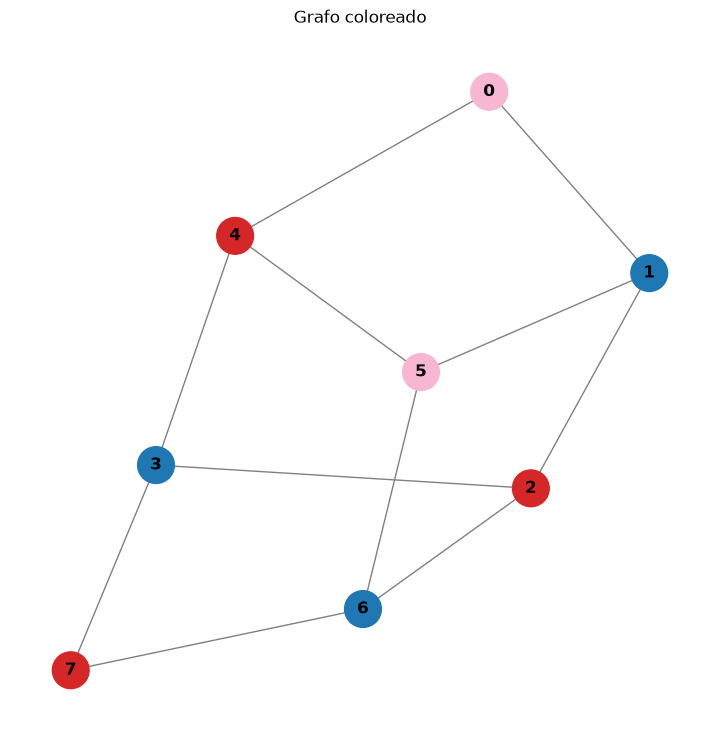

In [54]:
matriz = leer_grafo_archivo("grafo.txt")

k = 4  # número de colores
csp = GraphColoringCSP(matriz, k)
solucion = csp.resolver()

if solucion is None:
    print(f"No existe solución con {k} colores.")
else:
    print("Solución encontrada:")
    for v in sorted(solucion):
        print(f"  Nodo {v} -> color {solucion[v]}")
    print(f"\nNodos visitados: {csp.nodos_visitados}")
    print(f"Backtracks: {csp.backtracks}")
    dibujar_grafo(matriz, solucion, k)